# B0 inhomogeneity: spherical-harmonic fitting and gradient maps

Loads the aligned B0-inhomogeneity map and mask produced by `b0_mapping.ipynb`, fits a spherical-harmonic expansion, and plots the smooth B0 field and its spatial gradients.

In [1]:
# Project settings and paths: config.py is in the project root (this also makes the modules in src/ importable)
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())))
import config

import numpy as np
from pathlib import Path
from sympy import Znm, Symbol, simplify, lambdify
import sympy as sp
from scipy.optimize import lsq_linear

# Plotting related libraries
import matplotlib.pyplot as plt
import colorcet as cc

plt.style.use('dark_background')

# Define constants for throughout script
GAMMA = 42.577478518e6 # Hz/T

In [2]:
# Define directories
parent_dir = config.B0_MAPPING_DIR
deriv_dir = parent_dir / "derivatives"
plot_dir = parent_dir / "plots"

# Load the aligned B0-inhomogeneity map and mask saved by b0_mapping.ipynb
# Arrays are indexed [cor, sag, axi]
b0_data = np.load(deriv_dir / "b0_map_aligned.npz")
delta_B0_map_align = b0_data["delta_B0_map"]       # T, referenced to the mean B0
mask_align = b0_data["mask"].astype(bool)          # initial signal mask
spacing_mm = b0_data["spacing_mm"]                 # voxel size (mm)
f0_avg = float(b0_data["f0_avg"])                  # mean centre frequency (Hz)

print(f"Loaded map of shape {delta_B0_map_align.shape}, voxel spacing {spacing_mm} mm, mean f0 {f0_avg:.1f} Hz")

Loaded map of shape (31, 31, 31), voxel spacing [6.11111111 6.11111111 6.11111111] mm, mean f0 2704806.7 Hz


In [3]:
def plot_slices(array, axis, n=10, offset=0, title=None):

    shp = array.shape
    i_slice = shp[axis] // 2 + int(offset)

    fig, axes = plt.subplots(1, n, figsize=(2*n,5))

    for i in range(n):
        
        i_slice = shp[axis] // 2 + int(offset) + i
        
        if axis==0:
            s = [i_slice, slice(0,-1), slice(0,-1)]
        elif axis==1:
            s = [slice(0,-1), i_slice, slice(0,-1)]
        else:
            s = [slice(0,-1), slice(0,-1), i_slice]
        s = tuple(s)

        axes[i].imshow(array[s])
        axes[i].set_axis_off()

    fig.suptitle(title)
    plt.show()

Centre of image in voxels: 15/31, 15/31, 15/31


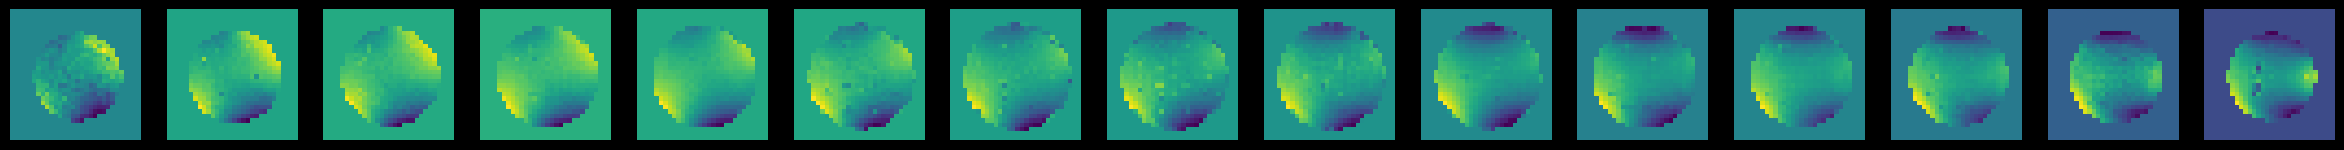

In [4]:
def centred_xyz(array, res):

    # This function creates X, Y ,Z arrays that have the same shape as the array passed to this function.
    # The function also applies an l1-norm filter to the array, replacing numbers other than 0 with 1.
    # It then uses this l1-image to find the centre of mass and shifts the x, y, z arrays to be centred.

    l1_img = array.copy()
    l1_img[abs(array)>0] = 1

    nxyz = l1_img.shape

    x_f = np.arange(nxyz[0], dtype=float)
    y_f = np.arange(nxyz[1], dtype=float)
    z_f = np.arange(nxyz[2], dtype=float)
    X_f, Y_f, Z_f = np.meshgrid(x_f, y_f, z_f, indexing='ij') # Indexing just ensures that the shape of X, Y, Z matches the l1_imaage.

    cx = np.round(np.sum(l1_img*X_f)/np.count_nonzero(l1_img), decimals=0)
    cy = np.round(np.sum(l1_img*Y_f)/np.count_nonzero(l1_img), decimals=0)
    cz = np.round(np.sum(l1_img*Z_f)/np.count_nonzero(l1_img), decimals=0)
    centre = np.array([cx, cy, cz])

    # Centre cartesian coordinate arrays
    X_f -= cx
    Y_f -= cy
    Z_f -= cz

    # Scale array to match image resolution
    X_f *= res[0]
    Y_f *= res[1]
    Z_f *= res[2]

    print(f'Centre of image in voxels: {cx:.0f}/{nxyz[0]}, {cy:.0f}/{nxyz[1]}, {cz:.0f}/{nxyz[2]}')

    return X_f, Y_f, Z_f

# We are now aligned with the other data arrays used to create other figures
# However this has the scanner axis indexed as [cor, sag, axi] = [y, z, x]

# Get a cleaner spherical mask centred on the noise mask
voxel_spacing = np.array(spacing_mm) * 1e-3 # metres
xv, yv, zv = centred_xyz(mask_align, res=voxel_spacing)

rv = np.sqrt(xv**2 + yv**2 + zv**2)
phantom_radius = 75e-3 # radius where there is signal in the phantom
sph_mask = rv < phantom_radius

# evaluate masks
db0_rough_mask = delta_B0_map_align.copy()
db0_rough_mask[~mask_align] = 0

db0_sph_mask = delta_B0_map_align.copy()
db0_sph_mask[~sph_mask] = 0

plot_data = np.concatenate([delta_B0_map_align, db0_rough_mask, db0_sph_mask], axis=1)
#px.imshow(plot_data, animation_frame=2, height=800)
plot_slices(db0_sph_mask, axis=2, n=15, offset=-7)

In [5]:
def make_lambdified_func(expr):
    
    # define expected variables
    x_s = Symbol("x", real=True)
    y_s = Symbol("y", real=True)
    z_s = Symbol("z", real=True)

    # Check if expression depends on x, y, or z
    free_vars = expr.free_symbols
    if not (x_s in free_vars or y_s in free_vars or z_s in free_vars):
        # It's a constant — wrap it in a function that returns an array of the same shape as input
        const_val = float(expr)
        return lambda x, y, z: np.full_like(x, const_val, dtype=np.float64)
    else:
        return lambdify([x_s, y_s, z_s], expr, modules='numpy')

def calc_sph_func_derv(n, m):

    x_s = Symbol("x", real=True)
    y_s = Symbol("y", real=True)
    z_s = Symbol("z", real=True)
    theta_s = Symbol("theta", real=True)
    phi_s = Symbol("phi", real=True)
    r_s = Symbol("r", real=True)

    # define cartesian to polar equations
    r_func = sp.sqrt(x_s**2 + y_s**2 + z_s**2)
    theta_func = sp.acos(z_s / r_func)
    phi_func = sp.atan2(y_s, x_s) + sp.pi

    Rnm_real = simplify(r_s**n * Znm(n, m, theta_s, phi_s).expand(func=True))
    Rnm_xyz = Rnm_real.subs({r_s: r_func, theta_s: theta_func, phi_s: phi_func})

    # Calculate differential equations
    Rnm_dx = simplify(sp.diff(Rnm_xyz, x_s))
    Rnm_dy = simplify(sp.diff(Rnm_xyz, y_s))
    Rnm_dz = simplify(sp.diff(Rnm_xyz, z_s))

    # Convert symbolic functions to numerical functions
    Rnm_func = make_lambdified_func(Rnm_xyz)
    Rnm_dx_func = make_lambdified_func(Rnm_dx)
    Rnm_dy_func = make_lambdified_func(Rnm_dy)
    Rnm_dz_func = make_lambdified_func(Rnm_dz)

    # Evaluate basis function & derivatives

    return Rnm_func, Rnm_dx_func, Rnm_dy_func, Rnm_dz_func

def basis_funcs_arrays(x_vals, y_vals, z_vals, nmax):
    
    eps = 1e-9 # avoids errors from calculating performance at origin
    x_vals = x_vals+eps
    y_vals = y_vals+eps
    z_vals = z_vals+eps

    basis_funcs = []
    basis_grad_x = []
    basis_grad_y = []
    basis_grad_z = []
    labels = []

    for n in range(nmax + 1):
        for m in range(-n, n + 1):

            Rnm_func, Rnm_dx_func, Rnm_dy_func, Rnm_dz_func = calc_sph_func_derv(n, m)

            Rnm_vals = np.nan_to_num(Rnm_func(x_vals, y_vals, z_vals), 0).real
            Rnm_dx_vals = np.nan_to_num(Rnm_dx_func(x_vals, y_vals, z_vals), 0).real
            Rnm_dy_vals = np.nan_to_num(Rnm_dy_func(x_vals, y_vals, z_vals), 0).real
            Rnm_dz_vals = np.nan_to_num(Rnm_dz_func(x_vals, y_vals, z_vals), 0).real

            basis_funcs.append(Rnm_vals)
            basis_grad_x.append(Rnm_dx_vals)
            basis_grad_y.append(Rnm_dy_vals)
            basis_grad_z.append(Rnm_dz_vals)
            labels.append(f"N:{n}, M:{m}")

    return basis_funcs, basis_grad_x, basis_grad_y, basis_grad_z, labels

def estimate_weightings(fieldmap, basis_fns, mask):
    
    # Vectorise data and basis functions
    b = fieldmap[mask].reshape(-1)
    A = np.array([fn[mask].reshape(-1) for fn in basis_fns]).T

    # linear least squares to fit the equation Ax = b where x is the weighting of the different spherical harmonics.
    sol = lsq_linear(A, b)
    x_coefs = sol.x

    return x_coefs

def weighted_array_sum(basis_arrays, x_coefs):

    vectorise = lambda basis_array : np.array([fn.reshape(-1) for fn in basis_array]).T
    vecs = vectorise(basis_arrays)
    shp = basis_arrays[0].shape
    weighted_sum = (vecs @ x_coefs).reshape(shp) # T/m
    return weighted_sum

# Use n=7 as a sensible order to go to, appears we get minimal benefits moving above this in terms of mean absolute error 
sph_order = 7
basis_sph, sph_gradx, sph_grady, sph_gradz, labels = basis_funcs_arrays(xv, yv, zv, nmax=sph_order)
x_coefs = estimate_weightings(delta_B0_map_align, basis_sph, sph_mask)

# estimate a smooth B0 field
b0_estimate = weighted_array_sum(basis_sph, x_coefs)

# Calculate gradient fields for each direction
# Note - currently the array is indexed as [sag, cor, axi]
g_cor = weighted_array_sum(sph_gradx, x_coefs)
g_sag = weighted_array_sum(sph_grady, x_coefs)
g_axi = weighted_array_sum(sph_gradz, x_coefs)

<lambdifygenerated-90>:2: RuntimeWarning: invalid value encountered in sqrt
  return (1/4)*z*sqrt(-770*x**2 - 770*y**2)*(-x**2*exp(6*1j*arctan2(y, x)) + x**2 - y**2*exp(6*1j*arctan2(y, x)) + y**2)*exp(-3*1j*arctan2(y, x))/sqrt(pi)
<lambdifygenerated-182>:2: RuntimeWarning: invalid value encountered in sqrt
  return (9/16)*z*sqrt(-385*x**2 - 385*y**2)*(-x**4*exp(10*1j*arctan2(y, x)) + x**4 - 2*x**2*y**2*exp(10*1j*arctan2(y, x)) + 2*x**2*y**2 - y**4*exp(10*1j*arctan2(y, x)) + y**4)*exp(-5*1j*arctan2(y, x))/sqrt(pi)
<lambdifygenerated-190>:2: RuntimeWarning: invalid value encountered in sqrt
  return (15/16)*z*sqrt(-35*x**2 - 35*y**2)*(3*x**4*exp(6*1j*arctan2(y, x)) - 3*x**4 + 6*x**2*y**2*exp(6*1j*arctan2(y, x)) - 6*x**2*y**2 - 8*x**2*z**2*exp(6*1j*arctan2(y, x)) + 8*x**2*z**2 + 3*y**4*exp(6*1j*arctan2(y, x)) - 3*y**4 - 8*y**2*z**2*exp(6*1j*arctan2(y, x)) + 8*y**2*z**2)*exp(-3*1j*arctan2(y, x))/sqrt(pi)


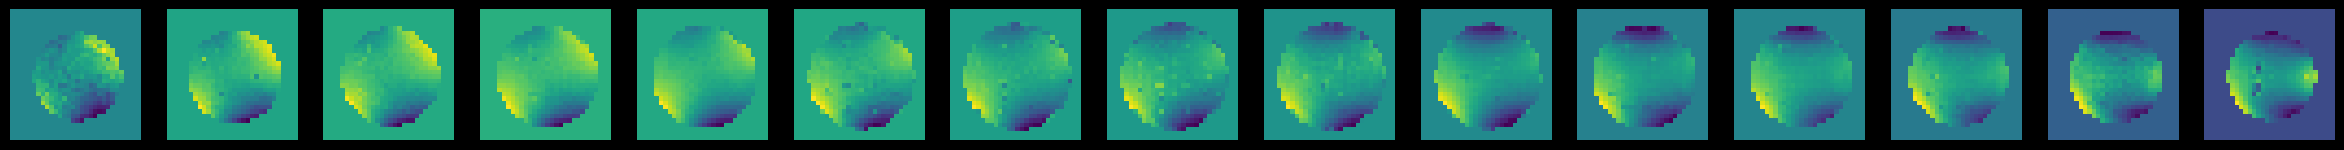

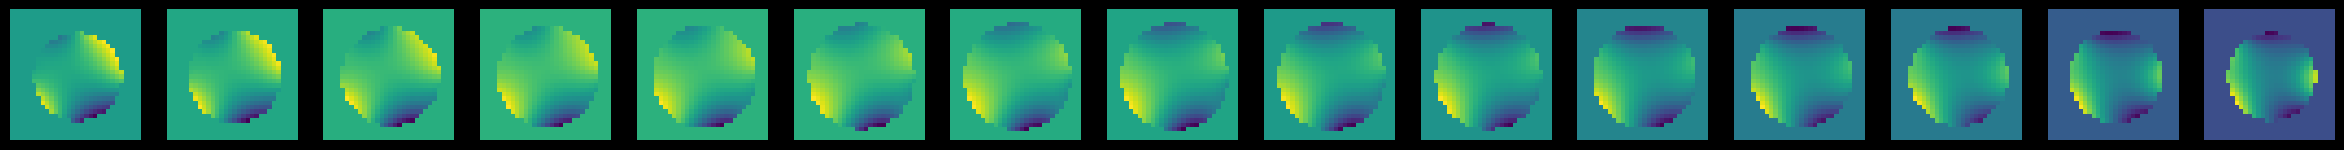

In [6]:
b0_est_masked = np.zeros_like(delta_B0_map_align)
b0_est_masked[sph_mask] = b0_estimate[sph_mask]

plot_data = np.concatenate([db0_sph_mask, b0_est_masked], axis=1)
lim = 0.1e-4
# px.imshow(plot_data, animation_frame=2, height=800, zmin=-lim, zmax=lim)
plot_slices(db0_sph_mask, axis=2, n=15, offset=-7)
plot_slices(b0_est_masked, axis=2, n=15, offset=-7)

In [7]:
# Use ppm and mT/m as units for plots
b0_estimate_ppm = b0_est_masked * 1e6 / (f0_avg / GAMMA) # Use ppm and mT/m as units for plots
g_sag_mt = g_sag * 1e3
g_cor_mt = g_cor * 1e3
g_axi_mt = g_axi * 1e3

# Calc gradient magnitude
g_norm = np.linalg.norm(np.stack([g_sag, g_cor, g_axi], axis=0), ord=2, axis=0)
g_norm_mt = g_norm * 1e3

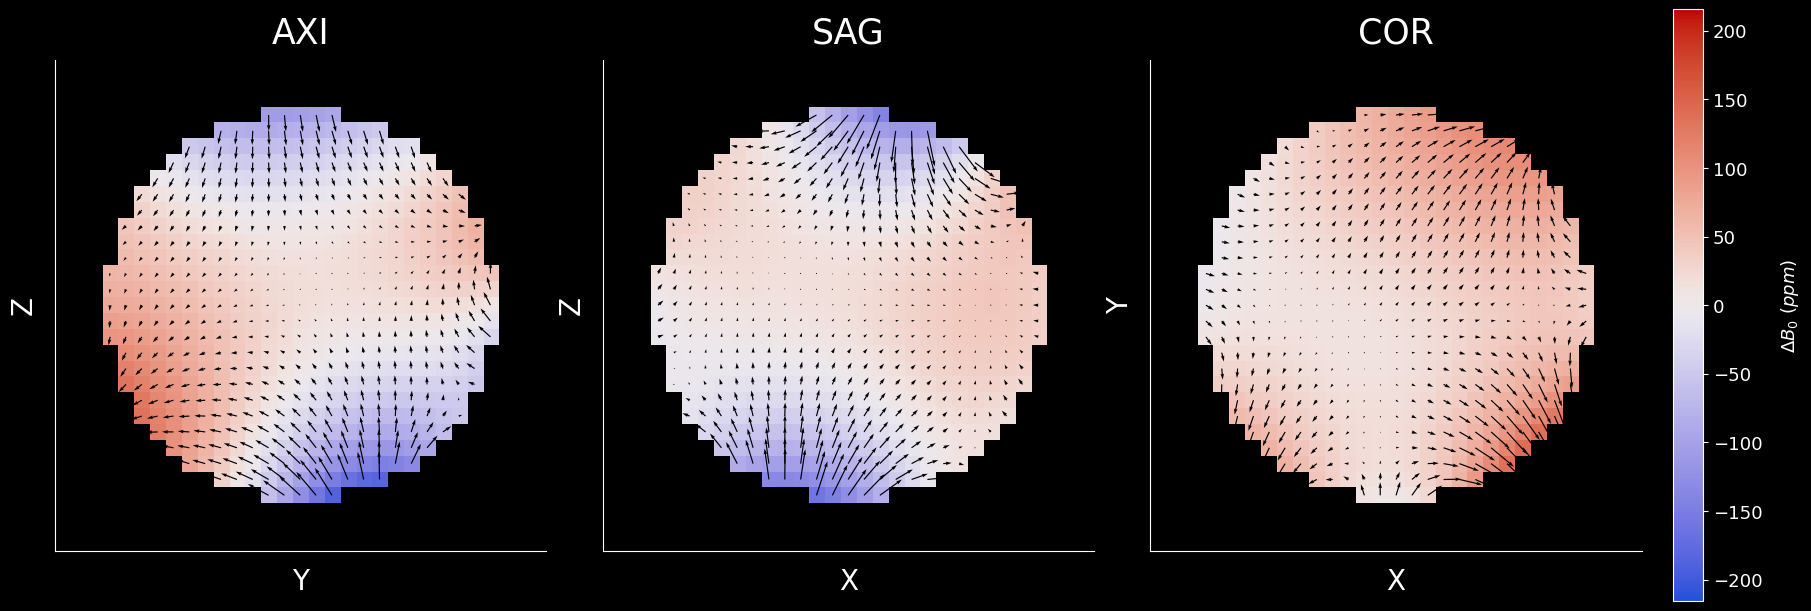

In [8]:
# B0 inhomogeneity plot with gradient fields overlayed
fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)

# Pixel-centre grid matching imshow(array): rows run along axis 0 (y), columns along axis 1 (x).
# Works for non-square slices; u/v passed to quiver must be (rows, cols) arrays of the x (column) and y (row) components.
def quiver_grid(shape):
    y, x = np.meshgrid(np.arange(shape[0]), np.arange(shape[1]), indexing='ij')
    return x, y

# Define font sizes
fs_axes = 20
fs_title = 25
fs_leg = 13
label_pad = 12
trim = 2

# Use symmetric colour scaling for B0 field
vmax = np.nanmax(np.abs(b0_estimate_ppm[sph_mask]))
vmin = -vmax

# ==============================================================
# AXI (X)
# ==============================================================
i_axi = sph_mask.shape[2] // 2
i_slice = tuple([slice(None), slice(None), i_axi])
b0_slice = np.where(sph_mask[i_slice],
                    b0_estimate_ppm[i_slice],
                    np.nan)

im = axes[0].imshow(
    b0_slice,
    vmin=vmin,
    vmax=vmax,
    cmap=cc.cm.coolwarm
)

# visualise Y and Z gradients
# However, imshow plots the first dim alond y and second dim along x
u = np.where(sph_mask[i_slice], g_sag_mt[i_slice], np.nan)
v = np.where(sph_mask[i_slice], g_cor_mt[i_slice], np.nan)

x, y = quiver_grid(b0_slice.shape)

axes[0].quiver(
    x,
    y,
    u,
    v,
    angles='xy',
    scale_units='xy',
    scale=None
)

axes[0].set_aspect('equal')
axes[0].set_title('AXI', fontsize=fs_title, pad=label_pad)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
axes[0].set_xlabel("Y", fontsize=fs_axes, labelpad=label_pad)
axes[0].set_ylabel("Z", fontsize=fs_axes, labelpad=label_pad)
axes[0].tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

# ==============================================================
# SAG (Y)
# ==============================================================
i_sag = sph_mask.shape[1] // 2
i_slice = tuple([slice(None), i_sag, slice(None)])
b0_slice = np.where(sph_mask[i_slice],
                    b0_estimate_ppm[i_slice],
                    np.nan)

im = axes[1].imshow(
    b0_slice,
    vmin=vmin,
    vmax=vmax,
    cmap=cc.cm.coolwarm
)

u = np.where(sph_mask[i_slice], g_axi_mt[i_slice], np.nan)
v = np.where(sph_mask[i_slice], g_cor_mt[i_slice], np.nan)

x, y = quiver_grid(b0_slice.shape)

axes[1].quiver(
    x,
    y,
    u,
    v,
    angles='xy',
    scale_units='xy',
    scale=None
)

axes[1].set_aspect('equal')
axes[1].set_title('SAG', fontsize=fs_title, pad=label_pad)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].set_xlabel("X", fontsize=fs_axes, labelpad=label_pad)
axes[1].set_ylabel("Z", fontsize=fs_axes, labelpad=label_pad)
axes[1].tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

# ==============================================================
# COR (Z)
# ==============================================================
i_cor = sph_mask.shape[0] // 2
i_slice = tuple([i_cor, slice(None), slice(None)])
b0_slice = np.where(sph_mask[i_slice],
                    b0_estimate_ppm[i_slice],
                    np.nan)

im = axes[2].imshow(
    b0_slice,
    vmin=vmin,
    vmax=vmax,
    cmap=cc.cm.coolwarm
)

u = np.where(sph_mask[i_slice], g_axi_mt[i_slice], np.nan)
v = np.where(sph_mask[i_slice], g_sag_mt[i_slice], np.nan)

x, y = quiver_grid(b0_slice.shape)

axes[2].quiver(
    x,
    y,
    u,
    v,
    angles='xy',
    scale_units='xy',
    scale=None
)

axes[2].set_aspect('equal')
axes[2].set_title('COR', fontsize=fs_title, pad=label_pad)
axes[2].spines['top'].set_visible(False)
axes[2].spines['right'].set_visible(False)
axes[2].set_xlabel("X", fontsize=fs_axes, labelpad=label_pad)
axes[2].set_ylabel("Y", fontsize=fs_axes, labelpad=label_pad)
axes[2].tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

cbar = fig.colorbar(im, ax=axes, location='right', shrink=1.0, pad=0.02)
cbar.set_label(r'$\Delta B_0\ (ppm)$', fontsize=fs_leg, labelpad=label_pad)
cbar.ax.tick_params(labelsize=fs_leg)

fmt = "jpg"
fig_fname = plot_dir / f"b0_maps.{fmt}"
fig.savefig(fig_fname, format=fmt, dpi=600, bbox_inches="tight", pad_inches=0.25)

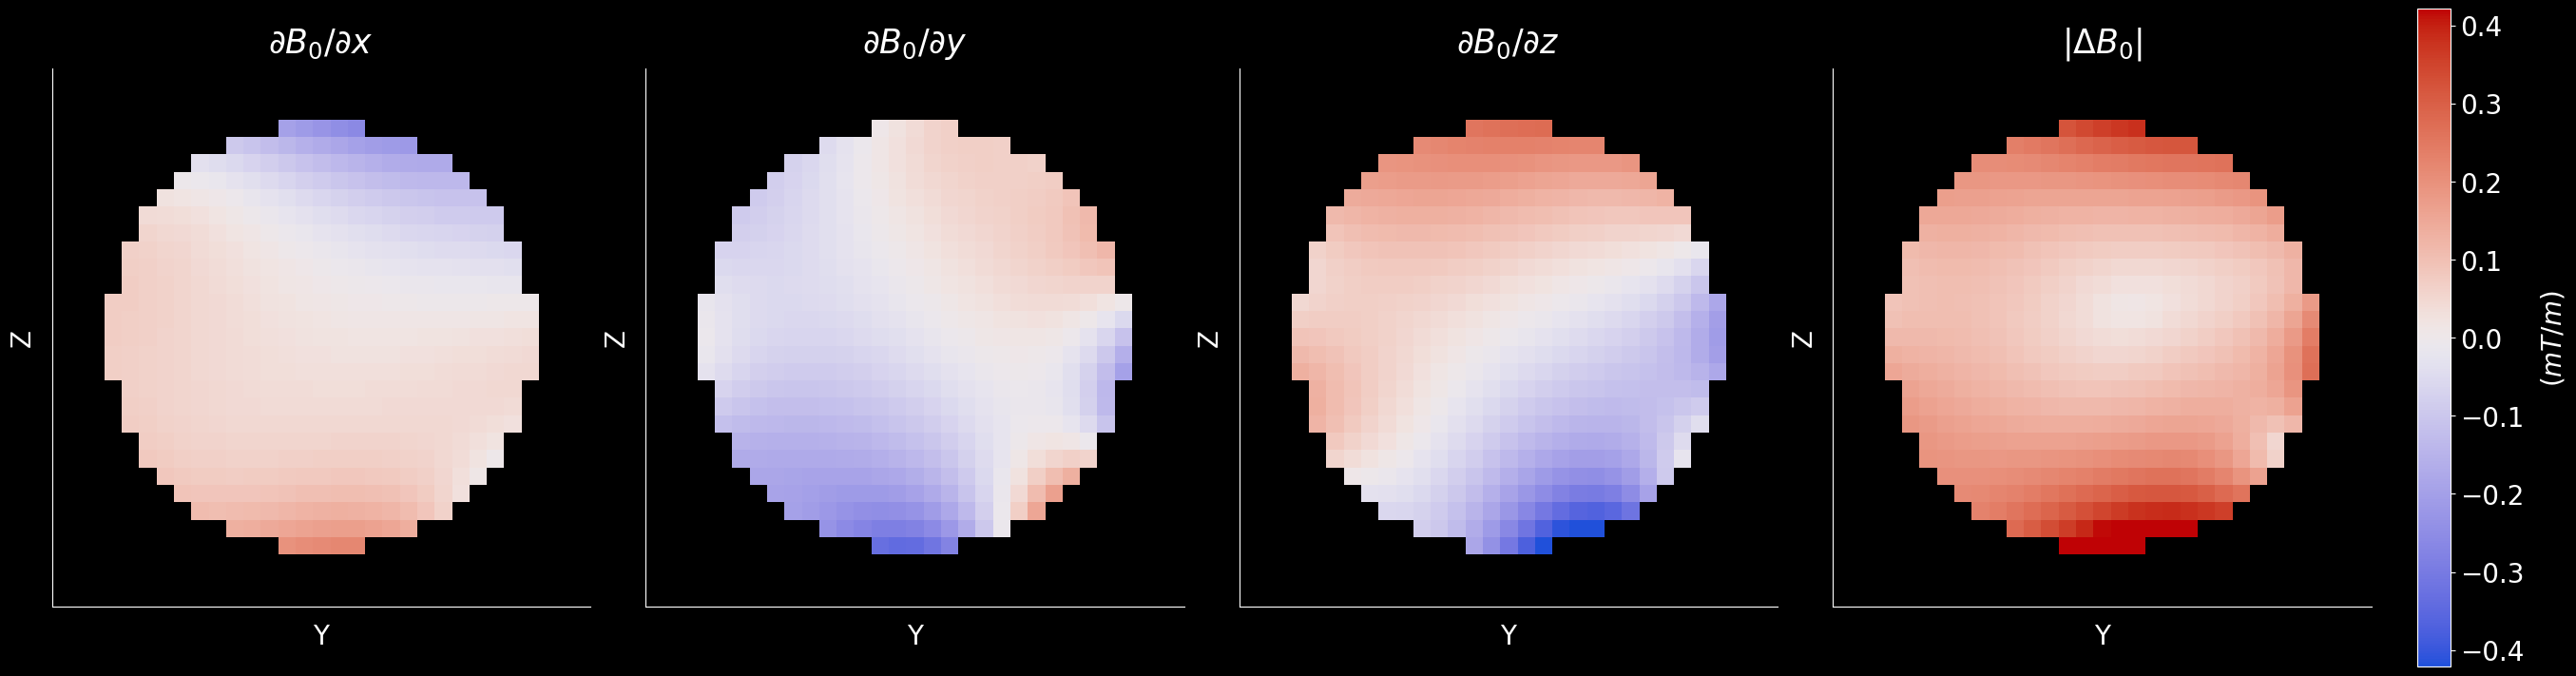

In [9]:
# Gradient plots in axial slice
fig, axes = plt.subplots(1, 4, figsize=(27, 7), constrained_layout=True, sharey=True)

# Formating variables
fs_axes = 20
fs_title = 25
fs_leg = 13
fs_contour = 10
label_pad = 12

# Use symmetric colour scaling for B0 field
vmax = np.percentile(g_norm_mt[sph_mask], 99)
vmin = -vmax

i_axi = sph_mask.shape[2] // 2
i_slice = tuple([slice(None), slice(None), i_axi])

# Lists to iterate over when plotting
plot_data_list = [g_axi_mt, g_sag_mt, g_cor_mt, g_norm_mt]
titles = [r"$\partial B_0 / \partial x$",
          r"$\partial B_0 / \partial y$",
          r"$\partial B_0 / \partial z$",
          r"$|\Delta B_0|$"]

for i, (ax, plotdata, ttl) in enumerate(zip(axes, plot_data_list, titles)):

    # Extract data
    plot_data_slice = np.where(sph_mask[i_slice],
                        plotdata[i_slice],
                        np.nan)

    im = ax.imshow(plot_data_slice, cmap=cc.cm.coolwarm, vmin=vmin, vmax=vmax)

    # Format
    ax.set_aspect('equal')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xlabel("Y", fontsize=fs_axes, labelpad=label_pad)
    ax.set_ylabel("Z", fontsize=fs_axes, labelpad=label_pad)
    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
    ax.set_title(ttl, fontsize=fs_title, pad=label_pad)

cbar = fig.colorbar(im, ax=axes, location='right', shrink=1.0, pad=0.02)
cbar.set_label(r'$(mT/m)$', fontsize=fs_axes, labelpad=label_pad)
cbar.ax.tick_params(labelsize=fs_axes)

fmt = "jpg"
fig_fname = plot_dir / f"static_grad_maps.{fmt}"
fig.savefig(fig_fname, format=fmt, dpi=600, bbox_inches="tight", pad_inches=0.5)